In [1]:
import numpy as np
import pandas as pd
import keras
import tensorflow as tf
import cv2
import os
import kagglehub
import random
from tqdm import tqdm
from keras import layers
from PIL import Image
from IPython.display import display
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

random.seed(1)
np.random.seed = 1

/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/sample_submission.csv
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0642.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0215.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0655.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0616.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0023.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/image_0798.tif
/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_n

In [7]:
IMG_WIDTH = 576
IMG_HEIGHT = 384
IMG_CHANNELS = 3

APO_TRAIN_PATH = '/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_imgs_v1/apo_images_new_model_v1/'
APO_MASK_PATH = '/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/'
ApoTrainFiles = sorted([f for f in os.listdir(APO_TRAIN_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
ApoMaskFiles = sorted([f for f in os.listdir(APO_MASK_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_MASK_PATH, f))])
FASC_TRAIN_PATH = "/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/fasc_imgs_v1/fasc_images_new_model_v1/"
FASC_MASK_PATH = "/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/fasc_masks_v1/fasc_masks_new_model_v1/"
FascTrainFiles = sorted([f for f in os.listdir(FASC_TRAIN_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
FascMaskFiles = sorted([f for f in os.listdir(FASC_MASK_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
#limiting the sample size here for faster testing
# ApoTrainFiles = ApoTrainFiles[:35]
# ApoMaskFiles = ApoMaskFiles[:35]
# ApoTestFiles = ApoTestFiles[:10]

Apo_X_Train = np.zeros((len(ApoTrainFiles), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.float32)
Apo_Y_Train = np.zeros((len(ApoTrainFiles), IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.float32)
Fasc_X_Train = np.zeros((len(FascTrainFiles), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.float32)
Fasc_Y_Train = np.zeros((len(FascTrainFiles), IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.float32)

for n, file in tqdm(enumerate(ApoTrainFiles), total=(len(ApoTrainFiles))):
    img = cv2.imread(APO_TRAIN_PATH + file)[:,:,:IMG_CHANNELS]
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    Apo_X_Train[n] = img
    img = cv2.imread(FASC_TRAIN_PATH + file)[:,:,:IMG_CHANNELS]
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    Fasc_X_Train[n] = img
    if os.path.exists(APO_MASK_PATH + file):
        mask = cv2.imread(APO_MASK_PATH + file, cv2.IMREAD_GRAYSCALE)    
        mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask_binary = (mask > 127).astype(np.float32)
        Apo_Y_Train[n] = np.expand_dims(mask_binary, axis=-1)
    if os.path.exists(FASC_MASK_PATH + file):
        mask = cv2.imread(FASC_MASK_PATH + file, cv2.IMREAD_GRAYSCALE)    
        mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask_binary = (mask > 127).astype(np.float32)
        Fasc_Y_Train[n] = np.expand_dims(mask_binary, axis=-1)
        
    

 43%|████▎     | 455/1048 [00:40<00:57, 10.33it/s][ WARN:0@307.056] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@307.056] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered
 44%|████▎     | 457/1048 [00:40<00:57, 10.23it/s][ WARN:0@307.255] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@307.255] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered
 44%|████▍     | 459/1048 [00:40<00:57, 10.21it/s][ WARN:0@307.451] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@307.451] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered
 44%|████▍     | 463/1048 [00:40<00:55, 10.46it/s][ WARN:0@307.827] global grfmt_tiff.cpp:122 

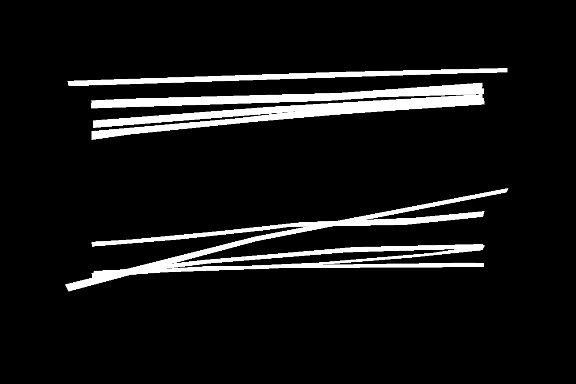

In [20]:
# matrix sanity check
img = np.squeeze(Apo_Y_Train[4]) #becomes single image shape
if img.dtype != np.uint8:
    if img.max() <= 1:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)
pilImg = Image.fromarray(img, mode='L')
display(pilImg)

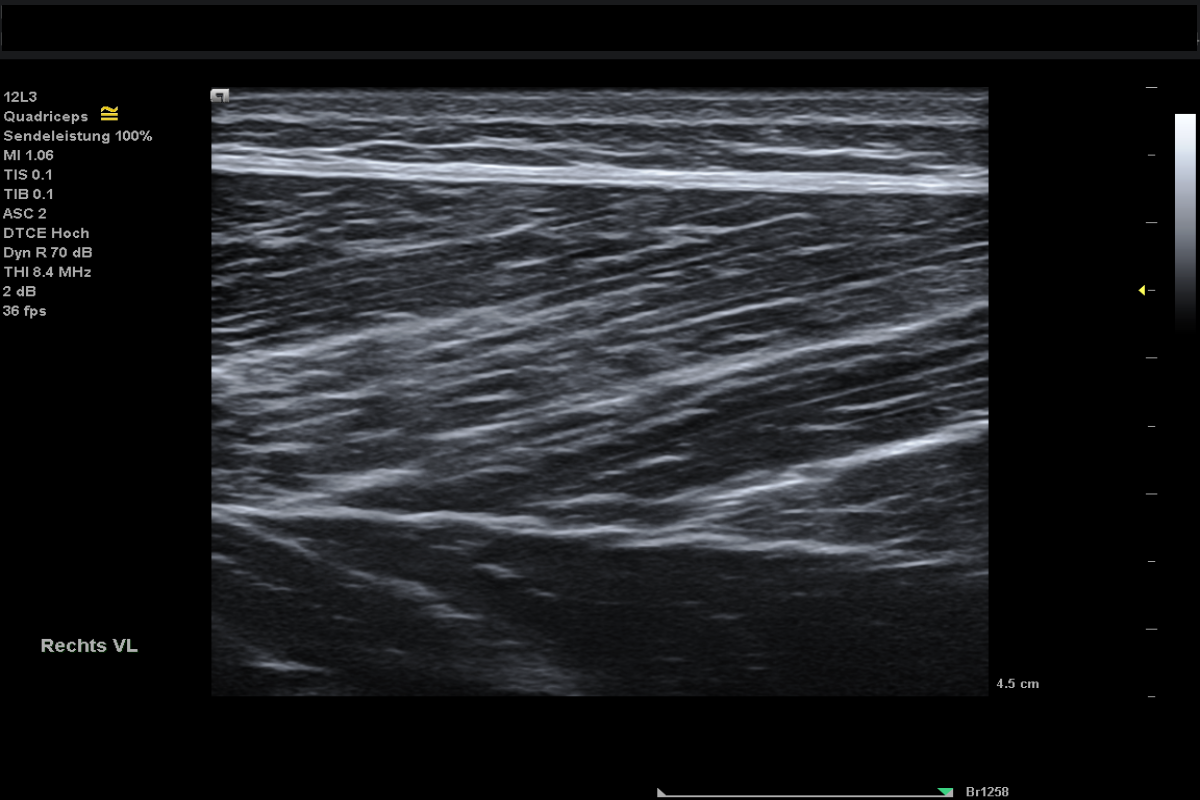

Size/Dimensions: (1200, 800)
Width: 1200
Height: 800
Color Mode: RGB


In [30]:
img = Image.open("/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2/test_set_v2/IMG_00001.tif")
display(img)
print(f"Size/Dimensions: {img.size}")
print(f"Width: {img.width}")
print(f"Height: {img.height}")
print(f"Color Mode: {img.mode}")

In [8]:
def buildModel():
    # Dimensions adjusted to be cleanly divisible by 128 (2^7) to avoid pooling rounding mismatches
    IMG_WIDTH = 576
    IMG_HEIGHT = 384
    IMG_CHANNELS = 3
    
    inputs = tf.keras.layers.Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))

    s = tf.keras.layers.Lambda(lambda x: x / 255)(inputs)
    conv1 = tf.keras.layers.Conv2D(16, (3, 3), activation="relu", kernel_initializer="he_normal", padding="same")(s)
    conv1 = tf.keras.layers.GroupNormalization(groups=2)(conv1)
    conv1 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv1)
    pool1 = tf.keras.layers.MaxPooling2D((2, 2))(conv1)

    conv2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool1)
    conv2 = tf.keras.layers.GroupNormalization(groups=2)(conv2)
    conv2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv2)
    pool2 = tf.keras.layers.MaxPooling2D((2, 2))(conv2)

    conv3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool2)
    conv3 = tf.keras.layers.GroupNormalization(groups=2)(conv3)
    conv3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv3)
    pool3 = tf.keras.layers.MaxPooling2D((2, 2))(conv3)

    conv4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool3)
    conv4 = tf.keras.layers.GroupNormalization(groups=2)(conv4)
    conv4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv4)
    pool4 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(conv4)

    conv5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool4)
    conv5 = tf.keras.layers.GroupNormalization(groups=2)(conv5)
    conv5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv5)

    #start upsample
    
    upsample6 = tf.keras.layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv5)
    upsample6 = tf.keras.layers.concatenate([upsample6, conv4])
    conv6 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample6)
    conv6 = tf.keras.layers.GroupNormalization(groups=2)(conv6)
    conv6 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv6)

    upsample7 = tf.keras.layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv6)
    upsample7 = tf.keras.layers.concatenate([upsample7, conv3])
    conv7 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample7)
    conv7 = tf.keras.layers.GroupNormalization(groups=2)(conv7)
    conv7 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv7)

    upsample8 = tf.keras.layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv7)
    upsample8 = tf.keras.layers.concatenate([upsample8, conv2])
    conv8 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample8)
    conv8 = tf.keras.layers.GroupNormalization(groups=2)(conv8)
    conv8 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv8)

    upsample9 = tf.keras.layers.Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(conv8)
    upsample9 = tf.keras.layers.concatenate([upsample9, conv1])
    conv9 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample9)
    conv9 = tf.keras.layers.GroupNormalization(groups=2)(conv9)
    conv9 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv9)

    outputs = tf.keras.layers.Conv2D(1, (1, 1), activation='sigmoid')(conv9)
    model = tf.keras.Model(inputs=[inputs], outputs=[outputs])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [9]:
strategy = tf.distribute.MirroredStrategy()
with strategy.scope():
    apoModel = buildModel()
apoModel.summary()

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 384, 576,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 384, 576,  │          0 │ input_layer[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 384, 576,  │        448 │ lambda[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 384, 576,  │         32 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 384, 576,  │      2,320 │ group_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 192, 288,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 192, 288,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 192, 288,  │         64 │ conv2d_2[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 192, 288,  │      9,248 │ group_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 96, 144,   │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 96, 144,   │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 96, 144,   │        128 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 96, 144,   │     36,928 │ group_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 48, 72,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 48, 72,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 48, 72,    │        256 │ conv2d_6[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 48, 72,    │    147,584 │ group_normalizat

 Total params: 1,942,577 (7.41 MB)

 Trainable params: 1,942,577 (7.41 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
checkpoint = tf.keras.callbacks.ModelCheckpoint("/kaggle/working/apo-u-net.h5", verbose=1, save_best_only=True)
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, monitor='val_loss'),
            tf.keras.callbacks.TensorBoard(log_dir='logs')]
results = apoModel.fit(Apo_X_Train, Apo_Y_Train, validation_split=0.25, batch_size=16, epochs=100, callbacks=callbacks)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

In [12]:
strategy = tf.distribute.MirroredStrategy()
with strategy.scope():
    fascModel = buildModel()
fascCheckpoint = tf.keras.callbacks.ModelCheckpoint("/kaggle/working/fasc-u-net.h5", verbose=1, save_best_only=True)
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, monitor='val_loss'),
            tf.keras.callbacks.TensorBoard(log_dir='logs')]
fascResults = fascModel.fit(Fasc_X_Train, Fasc_Y_Train, validation_split=0.25, batch_size=16, epochs=100, callbacks=callbacks)

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Epoch 1/100
INFO:tensorflow:Collective all_reduce tensors: 64 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
50/50 ━━━━━━━━━━━━━━━━━━━━ 40s 630ms/step - accuracy: 0.9851 - loss: 0.1078 - val_accuracy: 0.9985 - val_loss: 0.0281
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 528ms/step - accuracy: 0.9978 - loss: 0.0245 - val_accuracy: 0.9985 - val_loss: 0.0160
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 539ms/step - accuracy: 0.9978 - loss: 0.0177 - val_accuracy: 0.9985 - val_loss: 0.0123
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 542ms/step - accuracy: 0.9978 - loss: 0.0147 - val_accuracy: 0.9985 - val_loss: 0.0104
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 534ms/step - accuracy: 0.9978 - loss: 0.0130 - val_accuracy: 0.9985 - val_loss: 0.0091
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2

In [19]:
sharedInf = tf.keras.Input(shape=(384, 576, 3))
mask1 = fascModel(sharedInf)
mask2 = apoModel(sharedInf)
print("Type of mask1:", type(mask1))
print("Type of mask2:", type(mask2))
print("len 1: ", len(mask1))
print("len 2: ", len(mask2))

combinedOutputs = tf.keras.layers.Concatenate(axis=-1)([mask1[0], mask2[0]])
combinedModel = tf.keras.Model(inputs=sharedInf, outputs=combinedOutputs)
combinedModel.summary()

Type of mask1: <class 'list'>
Type of mask2: <class 'list'>
len 1:  1
len 2:  1


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 384, 576,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ (None, 384, 576,  │  1,942,577 │ input_layer_8[0]… │
│ (Functional)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 384, 576,  │  1,942,577 │ input_layer_8[0]… │
│ (Functional)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_13      │ (None, 384, 576,  │          0 │ functional_1[6][… │
│ (Concatenate)       │ 2)                │            │ functional[5][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,885,154 (14.82 MB)

 Trainable params: 3,885,154 (14.82 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
img = cv2.imread("/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2/test_set_v2/IMG_00005.tif")[:,:,:IMG_CHANNELS]
img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
img = np.expand_dims(img, axis=0)
testPredict = combinedModel.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


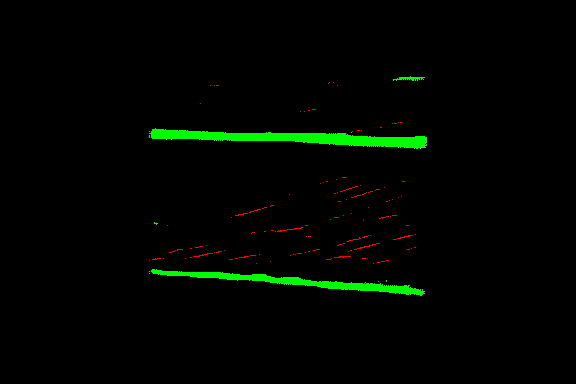

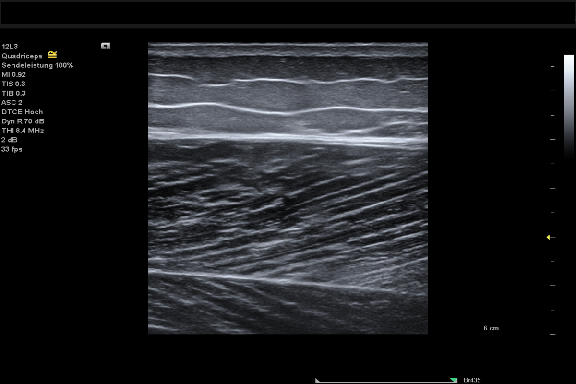

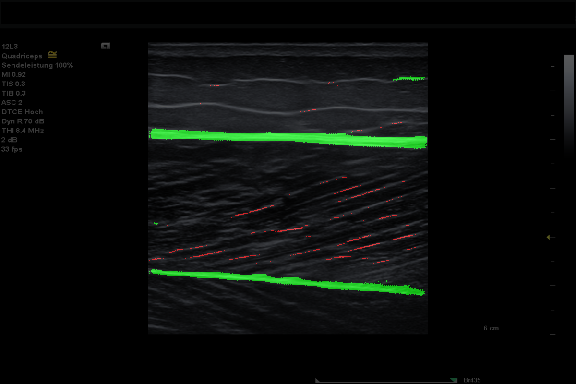

In [45]:
img = testPredict[0]
mask1 = (img[:, :, 0] > 0.5).astype(np.uint8) * 255
mask2 = (img[:, :, 1] > 0.5).astype(np.uint8) * 255
blank_channel = np.zeros_like(mask1)
rgb_array = np.stack([mask1, mask2, blank_channel], axis=-1)
combined_image = Image.fromarray(rgb_array, mode='RGB')
display(combined_image)
img = Image.open("/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2/test_set_v2/IMG_00005.tif")
img = img.resize((IMG_WIDTH, IMG_HEIGHT), resample=Image.NEAREST)
display(img)
overlay_result = Image.blend(combined_image, img, alpha=0.35)
display(overlay_result)


In [46]:
apoModel.export("/kaggle/working/apo")
fascModel.export("/kaggle/working/fasc")

INFO:tensorflow:Assets written to: /kaggle/working/apo/assets


INFO:tensorflow:Assets written to: /kaggle/working/apo/assets


Saved artifact at '/kaggle/working/apo'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 384, 576, 3), dtype=tf.float32, name='keras_tensor')]
Output Type:
  TensorSpec(shape=(None, 384, 576, 1), dtype=tf.float32, name=None)
Captures:
  133453109130832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108337680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108338256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108338640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108339408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108340368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108339792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108340944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108340176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133453108339600: TensorSpec(shape=(), dtype=tf.resource, name=Non

INFO:tensorflow:Assets written to: /kaggle/working/fasc/assets


Saved artifact at '/kaggle/working/fasc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 384, 576, 3), dtype=tf.float32, name='keras_tensor_50')]
Output Type:
  TensorSpec(shape=(None, 384, 576, 1), dtype=tf.float32, name=None)
Captures:
  133430548311376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950286288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950286096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950287056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950285520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950283216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950287440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950281296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950281872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451950285712: TensorSpec(shape=(), dtype=tf.resource, name